# Hidalga Social Content: Exploratory Data Analysis

**Source of truth:** `data/Hidalga_Master_Data_v3.xlsx`, read-only. This notebook never writes
to the master workbook. Any derived column is added to an in-memory copy only, and
**no rows are dropped**. Posts that need care (very small denominators, missing target)
are *flagged*, and every chart says how flagged posts were handled.

**Ground rules for comparisons**

- **Compare within a platform, not across platforms.** Facebook, Instagram and LinkedIn differ
  in audience size, in how each tool counts impressions, and in which engagement components exist
  (Instagram has no clicks or shares). Charts are faceted by platform, and each panel is read on
  its own. Different panels are *not* drawn on a shared y-scale unless stated.
- **Target:** `ENGAGEMENT_RATE_UNIFIED_PCT` = (reactions + comments + shares + clicks) / impressions × 100.
  On Instagram, likes stand in for reactions, and shares and clicks are absent.
- **Uncertainty is always shown.** Group means come with 95% bootstrap confidence intervals and
  the group size *n*. Small groups are expected (391 posts across 3 platforms), so wide intervals
  are information, not noise to hide.
- **Robustness without deletion.** Rates from posts with very few impressions are unstable
  (3 impressions with 2 engagements gives 66.7%). Next to each simple mean we show the
  *impression-weighted rate* (Σ engagements / Σ impressions), which down-weights tiny posts
  while keeping them in the data.

**Sections**
1. Setup and data loading
2. Data inventory and quality
3. The target: engagement-rate distributions
4. Content features within platform: pillar, ICP segment, format
5. Timing: day of week and time of day
6. Trends over time and the experiment period
7. Tag combinations (ICP × pillar)
8. Supporting data: followers, LinkedIn daily, visitors, Loomly clicks, Stories, competitors
9. Summary of findings and modeling implications

## 1. Setup and data loading

In [1]:
import hashlib
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

DATA_DIR = Path("../data")
MASTER = DATA_DIR / "Hidalga_Master_Data_v3.xlsx"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

TARGET = "ENGAGEMENT_RATE_UNIFIED_PCT"
PLATFORMS = ["Facebook", "Instagram", "LinkedIn"]
LOW_IMPRESSIONS = 10           # rates from posts below this are flagged as unstable
EXPERIMENT_START, EXPERIMENT_END = pd.Timestamp("2026-04-01"), pd.Timestamp("2026-09-30")
RNG_SEED = 26

**Chart style.** Platform identity uses three validated categorical slots (blue, orange, aqua). They pass
colorblind separation for all pairs, and every panel is also titled with the platform name, so color
is never the only cue. Grid and axes are kept light so the data stands out. Single-hue
blue ramps are used for magnitude (heatmaps).

In [2]:
PLATFORM_COLOR = {"Facebook": "#2a78d6", "Instagram": "#eb6834", "LinkedIn": "#1baf7a"}
INK, INK_2, INK_MUTED = "#0b0b0b", "#52514e", "#8a8984"
GRID, SURFACE = "#e6e5e0", "#fcfcfb"
EXPERIMENT_FILL = "#ecebe6"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": GRID, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.major.size": 0, "ytick.major.size": 0,
    "text.color": INK, "legend.frameon": False, "lines.linewidth": 2,
})


def save(fig, name):
    """Save a figure for the report alongside showing it inline."""
    fig.savefig(FIG_DIR / f"{name}.png")


def platform_panels(nrows=1, height=3.6, width=4.4, sharey=False, sharex=False):
    """One panel per platform, titled with the platform name (identity never color-only)."""
    fig, axes = plt.subplots(nrows, 3, figsize=(width * 3, height * nrows), sharey=sharey, sharex=sharex,
                             squeeze=False)
    for ax, p in zip(axes[0], PLATFORMS):
        ax.set_title(p, color=INK)
    return fig, axes if nrows > 1 else axes[0]

**Load the master (read-only).** We record the file's SHA-256 so it can be checked at the end of the
notebook to confirm nothing changed it.

In [3]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

MASTER_SHA = sha256(MASTER)
sheets = pd.read_excel(MASTER, sheet_name=None)
raw_posts = sheets["Social Posts (unified)"]
posts = raw_posts.copy()   # all derived columns go on this in-memory copy

print(f"{MASTER.name}  sha256={MASTER_SHA[:12]}…")
print(f"{len(sheets)} sheets · Social Posts: {len(posts)} rows × {posts.shape[1]} columns")

Hidalga_Master_Data_v3.xlsx  sha256=030bd10386b1…
16 sheets · Social Posts: 391 rows × 28 columns


## 2. Data inventory and quality

### 2.1 What's in the workbook

In [4]:
SHEET_ROLE = {
    "Social Posts (unified)": "one row per published post: content tags + metrics (main table)",
    "LinkedIn Posts (detail)": "LinkedIn-native per-post export (views, CTR, follows)",
    "LinkedIn Daily Metrics": "LinkedIn page, daily impressions/engagement",
    "Visitor Daily Metrics": "LinkedIn page visitors, daily",
    "Visitor Demographics": "LinkedIn visitor breakdown by job function, industry, etc.",
    "Follower Counts": "monthly per-channel rollup from Loomly",
    "Loomly Clicks": "per short-link click totals",
    "Instagram Stories": "Stories (separate content type)",
    "LinkedIn New Followers (daily)": "daily new LinkedIn followers",
    "Competitors": "competitor page benchmark, one annual snapshot",
}
inventory = pd.DataFrame([
    {"sheet": name, "rows": len(df), "columns": df.shape[1], "role": SHEET_ROLE.get(name, "QA / audit log")}
    for name, df in sheets.items()
])
display(inventory)

,sheet,rows,columns,role
0,Social Posts (unified),391,28,one row per published post: content tags + metrics (main...
1,LinkedIn Posts (detail),142,24,"LinkedIn-native per-post export (views, CTR, follows)"
2,LinkedIn Daily Metrics,365,24,"LinkedIn page, daily impressions/engagement"
3,Visitor Daily Metrics,365,26,"LinkedIn page visitors, daily"
4,Visitor Demographics,132,4,"LinkedIn visitor breakdown by job function, industry, etc."
5,Follower Counts,27,8,monthly per-channel rollup from Loomly
6,Loomly Clicks,95,8,per short-link click totals
7,Instagram Stories,20,13,Stories (separate content type)
8,LinkedIn New Followers (daily),365,6,daily new LinkedIn followers
9,Competitors,10,9,"competitor page benchmark, one annual snapshot"


### 2.2 Social Posts: column profile
Null counts and types per column. The metric columns are *structurally* empty on some platforms
(e.g. Instagram has no `CLICKS`, Facebook/LinkedIn have no `REACH`), so we also look at null counts by platform.

In [5]:
profile = pd.DataFrame({
    "dtype": posts.dtypes.astype(str),
    "non_null": posts.notna().sum(),
    "null": posts.isna().sum(),
    "unique": posts.nunique(),
})
display(profile)

METRICS = ["IMPRESSIONS", "REACH", "LIKES", "REACTIONS", "COMMENTS", "SHARES", "CLICKS", "SAVES",
           "VIDEO_VIEWS", "REELS_PLAYS", "ENGAGEMENT_RAW", TARGET]
print("Non-null metric values by platform (structural gaps, not missing data):")
display(posts.groupby("PLATFORM")[METRICS].count().T)

,dtype,non_null,null,unique
SOURCE_FILE,object,391,0,4
PLATFORM,object,391,0,3
DATE,datetime64[ns],391,0,146
POST_TIME,object,391,0,114
FORMAT,object,391,0,7
POST_TITLE,object,391,0,166
POST_BODY,object,391,0,351
LABELS_RAW,object,391,0,83
ICP_SEGMENTS,object,391,0,12
CONTENT_PILLAR,object,391,0,9


Non-null metric values by platform (structural gaps, not missing data):


PLATFORM,Facebook,Instagram,LinkedIn
IMPRESSIONS,124,130,137
REACH,0,130,0
LIKES,0,130,0
REACTIONS,124,0,137
COMMENTS,124,130,137
SHARES,124,0,137
CLICKS,124,0,137
SAVES,0,130,0
VIDEO_VIEWS,124,0,0
REELS_PLAYS,0,130,0


### 2.3 Derived columns (in memory only)

| column | definition |
|---|---|
| `DATE_TS`, `MONTH`, `DOW`, `HOUR` | parsed from `DATE` and `POST_TIME` (all times are US Central, CDT/CST) |
| `TIME_BLOCK` | Morning (<11), Midday (11–13), Afternoon (14–16), Evening (17+) |
| `ENGAGEMENTS` | the unified-rate numerator: reactions (likes on IG) + comments + shares + clicks |
| `ICP__*`, `PILLAR__*` | one 0/1 column per ICP segment / content pillar (posts can carry several) |
| `N_ICP`, `N_PILLAR` | how many segments / pillars a post is tagged with |
| `FLAG_LOW_IMPRESSIONS` | impressions < 10: rate is unstable, kept but flagged |
| `FLAG_NO_TARGET` | target is null (0 impressions) |
| `FLAG_EXPERIMENT` | copy of `IN_EXPERIMENT_PERIOD` |

In [6]:
posts["DATE_TS"] = pd.to_datetime(posts["DATE"])
posts["MONTH"] = posts["DATE_TS"].dt.to_period("M")
DOW_ORDER = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
posts["DOW"] = pd.Categorical(posts["DATE_TS"].dt.strftime("%a"), categories=DOW_ORDER, ordered=True)

clock = pd.to_datetime(posts["POST_TIME"].str.replace(r"\s+C[DS]T$", "", regex=True), format="%I:%M %p",
                       errors="coerce")
posts["HOUR"] = clock.dt.hour
BLOCK_ORDER = ["Morning (<11)", "Midday (11–13)", "Afternoon (14–16)", "Evening (17+)"]
posts["TIME_BLOCK"] = pd.Categorical(
    pd.cut(posts["HOUR"], bins=[-1, 10, 13, 16, 24], labels=BLOCK_ORDER).astype(str),
    categories=BLOCK_ORDER, ordered=True)

NUMERATOR = {"Facebook": ["REACTIONS", "COMMENTS", "SHARES", "CLICKS"],
             "Instagram": ["LIKES", "COMMENTS", "SHARES", "CLICKS"],
             "LinkedIn": ["REACTIONS", "COMMENTS", "SHARES", "CLICKS"]}
posts["ENGAGEMENTS"] = [
    sum(0 if pd.isna(r[c]) else r[c] for c in NUMERATOR[r["PLATFORM"]]) for _, r in posts.iterrows()]


def split_tags(s):
    return [] if pd.isna(s) else [t.strip() for t in str(s).split(";") if t.strip()]

ICPS = sorted({t for s in posts["ICP_SEGMENTS"] for t in split_tags(s)})
PILLARS = sorted({t for s in posts["CONTENT_PILLAR"] for t in split_tags(s)})
for t in ICPS:
    posts[f"ICP__{t}"] = posts["ICP_SEGMENTS"].map(lambda s: int(t in split_tags(s)))
for t in PILLARS:
    posts[f"PILLAR__{t}"] = posts["CONTENT_PILLAR"].map(lambda s: int(t in split_tags(s)))
posts["N_ICP"] = posts[[f"ICP__{t}" for t in ICPS]].sum(axis=1)
posts["N_PILLAR"] = posts[[f"PILLAR__{t}" for t in PILLARS]].sum(axis=1)

posts["FLAG_LOW_IMPRESSIONS"] = posts["IMPRESSIONS"].fillna(0) < LOW_IMPRESSIONS
posts["FLAG_NO_TARGET"] = posts[TARGET].isna()
posts["FLAG_EXPERIMENT"] = posts["IN_EXPERIMENT_PERIOD"].astype(bool)

assert len(posts) == len(raw_posts), "row count must never change"
print("POST_TIME unparsed:", posts["HOUR"].isna().sum())
print("ICP segments:", ICPS)
print("Pillars:", PILLARS)

POST_TIME unparsed: 0
ICP segments: ['Oncology Clinic Leader', 'Oncology Financial Leader', 'Oncology Operations Leader', 'Oncology Technical Leader']
Pillars: ['Events & Partnerships', 'Patient-Centered Storytelling', 'Product Development & Innovations', 'Team Spotlights & Company Culture', 'Thought Leadership & Industry Insights']


**Sanity check:** the in-memory numerator / impressions must reproduce the stored target exactly.

In [7]:
recomputed = (posts["ENGAGEMENTS"] / posts["IMPRESSIONS"].where(posts["IMPRESSIONS"] > 0) * 100).round(4)
mismatch = (recomputed - posts[TARGET]).abs() > 1e-3
print(f"recomputed vs stored target, mismatches: {int(mismatch.sum())} of {posts[TARGET].notna().sum()}")

recomputed vs stored target, mismatches: 0 of 390


### 2.4 Coverage and flags by platform

In [8]:
coverage = posts.groupby("PLATFORM").agg(
    posts=("PLATFORM", "size"),
    first=("DATE_TS", "min"), last=("DATE_TS", "max"),
    no_target=("FLAG_NO_TARGET", "sum"),
    low_impressions=("FLAG_LOW_IMPRESSIONS", "sum"),
    zero_engagement=(TARGET, lambda s: int((s == 0).sum())),
    in_experiment=("FLAG_EXPERIMENT", "sum"),
    multi_icp=("N_ICP", lambda s: int((s > 1).sum())),
    multi_pillar=("N_PILLAR", lambda s: int((s > 1).sum())),
    li_native_metrics=("ENGAGEMENT_SOURCE", lambda s: int(s.str.startswith("LinkedIn").sum())),
)
coverage["first"] = coverage["first"].dt.date
coverage["last"] = coverage["last"].dt.date
display(coverage)

,posts,first,last,no_target,low_impressions,zero_engagement,in_experiment,multi_icp,multi_pillar,li_native_metrics
PLATFORM,,,,,,,,,,
Facebook,124,2025-10-30,2026-09-29,1,24,13,73,36,4,0
Instagram,130,2025-09-23,2026-09-24,0,2,0,71,40,5,0
LinkedIn,137,2025-10-02,2026-09-29,0,1,1,73,43,4,127


## 3. The target: engagement-rate distributions

Helpers used from here on:
- `boot_ci`: 95% percentile bootstrap CI for a mean (2,000 resamples, fixed seed).
- `summarize`: per group: *n*, mean with CI, median, and the impression-weighted rate
  (Σ engagements / Σ impressions × 100). The weighted rate is our robustness check: it keeps every post
  but lets a 3-impression post count for 3 impressions, not as a full observation.

In [9]:
rng = np.random.default_rng(RNG_SEED)


def boot_ci(x, n_boot=2000, level=0.95):
    x = np.asarray(pd.Series(x).dropna(), dtype=float)
    if len(x) < 2:
        return (np.nan, np.nan)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    a = (1 - level) / 2
    return tuple(np.quantile(means, [a, 1 - a]))


def summarize(df, by):
    rows = []
    for key, g in df.groupby(by, observed=True):
        y = g[TARGET].dropna()
        lo, hi = boot_ci(y)
        imp = g.loc[g[TARGET].notna(), "IMPRESSIONS"].sum()
        rows.append({**dict(zip([by] if isinstance(by, str) else by, key if isinstance(key, tuple) else (key,))),
                     "n": len(y), "mean": y.mean(), "ci_lo": lo, "ci_hi": hi, "median": y.median(),
                     "weighted": g.loc[g[TARGET].notna(), "ENGAGEMENTS"].sum() / imp * 100 if imp else np.nan})
    return pd.DataFrame(rows)

### 3.1 Summary statistics by platform
These numbers describe each platform on its own scale. They are **not** a ranking of platforms. The Instagram
rate lacks clicks and shares, and each tool counts impressions differently.

In [10]:
target_summary = posts.groupby("PLATFORM")[TARGET].describe(percentiles=[.1, .25, .5, .75, .9]).round(2)
target_summary["weighted_rate"] = summarize(posts, "PLATFORM").set_index("PLATFORM")["weighted"].round(2)
target_summary["zero_rate_posts"] = posts.groupby("PLATFORM")[TARGET].apply(lambda s: int((s == 0).sum()))
display(target_summary)

,count,mean,std,min,10%,25%,50%,75%,90%,max,weighted_rate,zero_rate_posts
PLATFORM,,,,,,,,,,,,
Facebook,123.0,13.71,10.07,0.00,0.26,6.67,12.90,20.00,26.33,50.00,10.28,13
Instagram,130.0,17.79,8.88,0.28,7.86,12.88,16.87,21.43,27.78,60.00,9.28,0
LinkedIn,137.0,9.38,8.92,0.00,3.41,5.10,7.21,11.11,15.29,66.67,8.28,1


### 3.2 Distribution of the engagement rate
One histogram per platform (2.5-point bins). Each panel has its own y-axis, and the dashed line is the platform
median. Low-impression posts are included and stacked on top in a lighter shade, so their contribution is visible.

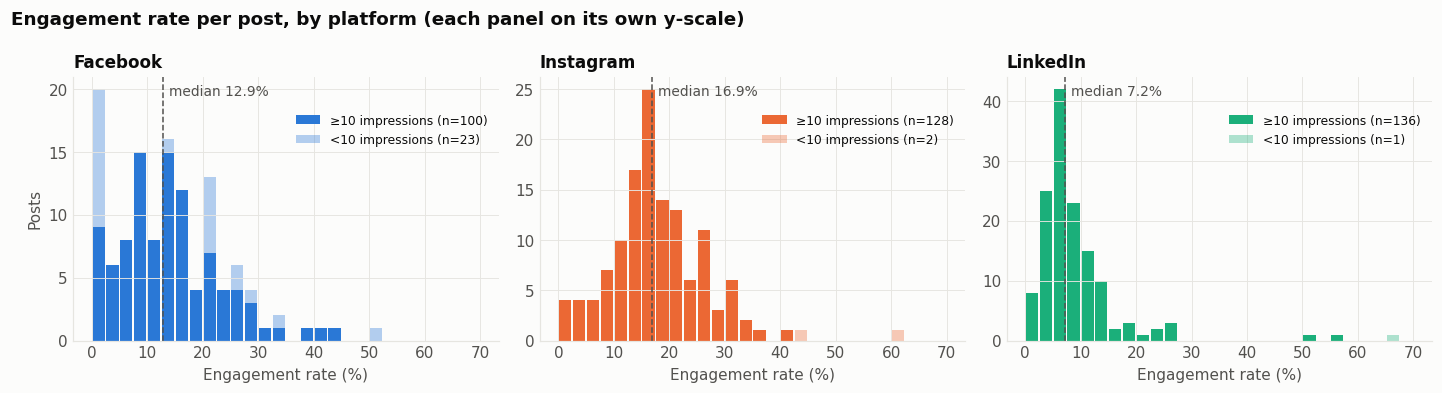

In [11]:
bins = np.arange(0, 72.5, 2.5)
fig, axes = platform_panels()
for ax, p in zip(axes, PLATFORMS):
    d = posts[posts["PLATFORM"] == p]
    stable = d.loc[~d["FLAG_LOW_IMPRESSIONS"], TARGET].dropna()
    low = d.loc[d["FLAG_LOW_IMPRESSIONS"], TARGET].dropna()
    ax.hist([stable, low], bins=bins, stacked=True, rwidth=0.88,
            color=[PLATFORM_COLOR[p], PLATFORM_COLOR[p] + "59"],
            label=[f"≥{LOW_IMPRESSIONS} impressions (n={len(stable)})", f"<{LOW_IMPRESSIONS} impressions (n={len(low)})"])
    med = d[TARGET].median()
    ax.axvline(med, color=INK_2, ls="--", lw=1)
    ax.annotate(f"median {med:.1f}%", (med, 1), xycoords=("data", "axes fraction"), xytext=(4, -12),
                textcoords="offset points", color=INK_2, fontsize=9)
    ax.set_xlabel("Engagement rate (%)")
    ax.legend(fontsize=8, loc="upper right", bbox_to_anchor=(1, 0.9))
axes[0].set_ylabel("Posts")
fig.suptitle("Engagement rate per post, by platform (each panel on its own y-scale)", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
save(fig, "03_target_hist")
plt.show()

### 3.3 Impressions: the denominator
Audience size differs by an order of magnitude between platforms, which is one more reason not to compare rates
across them. Log scale on x.

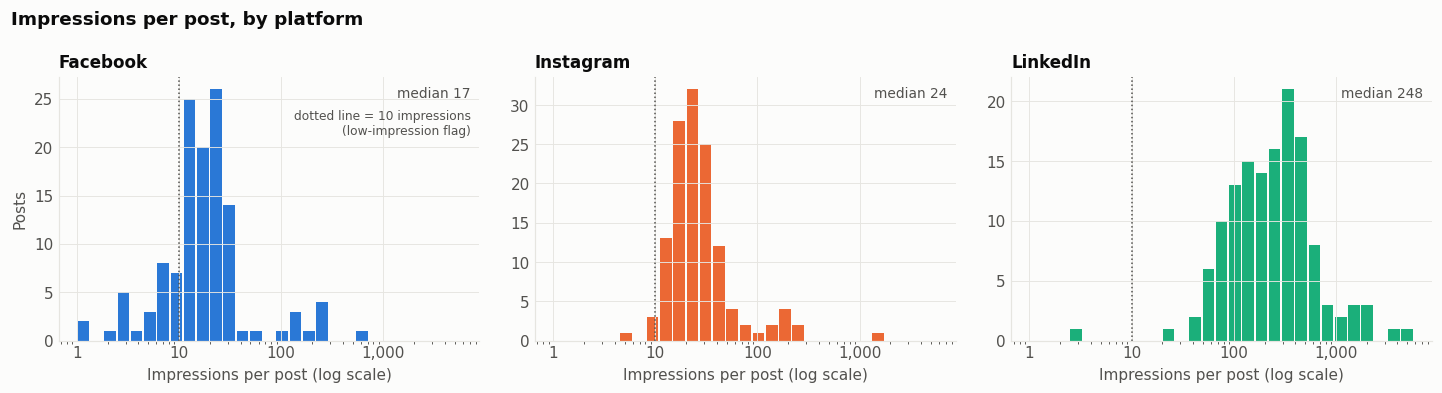

In [12]:
fig, axes = platform_panels()
log_bins = np.logspace(0, np.log10(posts["IMPRESSIONS"].max() + 1), 30)
for ax, p in zip(axes, PLATFORMS):
    imp = posts.loc[posts["PLATFORM"] == p, "IMPRESSIONS"]
    ax.hist(imp.clip(lower=1), bins=log_bins, color=PLATFORM_COLOR[p], rwidth=0.88)
    ax.set_xscale("log")
    ax.axvline(LOW_IMPRESSIONS, color=INK_2, ls=":", lw=1)
    ax.annotate(f"median {imp.median():.0f}", (0.98, 0.92), xycoords="axes fraction", ha="right",
                color=INK_2, fontsize=9)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_xlabel("Impressions per post (log scale)")
axes[0].set_ylabel("Posts")
axes[0].annotate(f"dotted line = {LOW_IMPRESSIONS} impressions\n(low-impression flag)", (0.98, 0.78),
                 xycoords="axes fraction", ha="right", color=INK_2, fontsize=8)
fig.suptitle("Impressions per post, by platform", x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout()
save(fig, "03_impressions_hist")
plt.show()

### 3.4 Rate vs. impressions: where the instability lives
Each dot is a post. Posts below the low-impression threshold are drawn hollow. Small denominators produce
the spread at the left edge (rates jump in big steps when impressions are tiny). This is the reason for
showing an impression-weighted rate next to every simple mean.

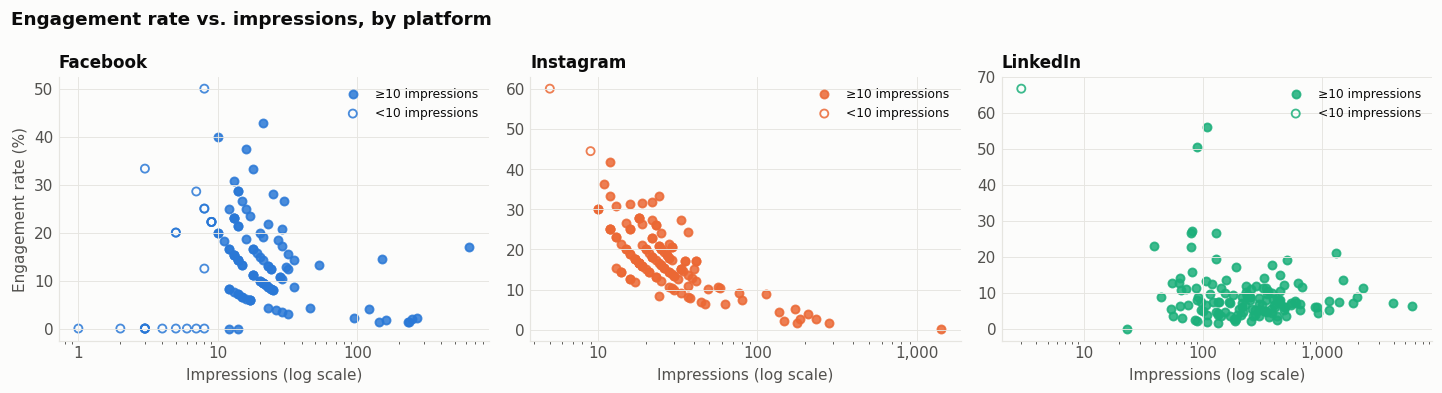

In [13]:
fig, axes = platform_panels()
for ax, p in zip(axes, PLATFORMS):
    d = posts[(posts["PLATFORM"] == p) & posts[TARGET].notna()]
    for low, sub in d.groupby("FLAG_LOW_IMPRESSIONS"):
        ax.scatter(sub["IMPRESSIONS"].clip(lower=1), sub[TARGET], s=28, linewidths=1.2,
                   facecolors="none" if low else PLATFORM_COLOR[p], edgecolors=PLATFORM_COLOR[p],
                   alpha=0.85, label=f"<{LOW_IMPRESSIONS} impressions" if low else f"≥{LOW_IMPRESSIONS} impressions")
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_xlabel("Impressions (log scale)")
    ax.legend(fontsize=8, loc="upper right")
axes[0].set_ylabel("Engagement rate (%)")
fig.suptitle("Engagement rate vs. impressions, by platform", x=0.01, ha="left", fontsize=12,
             fontweight="semibold")
fig.tight_layout()
save(fig, "03_rate_vs_impressions")
plt.show()

**What section 3 shows**

- **Facebook** has the widest spread and most of the dataset's fragile rates. 23 of its 123 scored posts have
  fewer than 10 impressions, and those account for most of the 0% bin. A separate group of higher-reach posts
  (≈100–300 impressions) sits near 2%. Section 4.3 shows these are mostly **videos**.
- **Instagram** shows a strong *inverse* relationship between reach and rate. Posts reaching 100+ accounts
  engage at a fraction of the rate of 15–30-impression posts. This is why its simple mean (17.8%) is almost double
  its impression-weighted rate (9.3%). The rate is partly a function of audience size.
- **LinkedIn** rates are concentrated (median 7.2%, IQR 5.1–11.1%) and roughly flat across impressions, with a
  few outliers above 50%.
- The curved bands of dots are a counting artifact: with small denominators a rate can only take values
  k / impressions (1/12, 2/12, …).

**Implication for modeling:** include log-impressions (or model engagements as counts with an impressions
exposure/offset) rather than treating the rate as independent of reach, especially on Instagram.

## 4. Content features within platform

For each feature, every platform gets its own panel. Each row shows:
- **●** simple mean rate with its **95% bootstrap CI** (the horizontal line),
- **◇** impression-weighted rate (robustness check, which down-weights tiny posts),
- **n** = posts in the group,
- a dashed vertical line at the platform's overall median, to anchor the panel.

Read each panel on its own. A category whose CI overlaps the others is not distinguishable from them with
this sample.

**Multi-label note:** posts can carry several ICP segments and pillars. In the ICP and pillar charts, a post
appears in *every* group it is tagged with, so groups overlap and their *n* values sum to more than the post count.

In [14]:
def dot_ci_panels(df, feature, order=None, title="", label_width=34, name=None, absent_label="not on platform"):
    """Mean ± 95% CI and impression-weighted rate per category, one panel per platform."""
    s_all = summarize(df, ["PLATFORM", feature])
    cats = order or sorted(s_all[feature].unique())
    height = 0.42 * len(cats) + 1.4
    fig, axes = platform_panels(height=height, width=4.6, sharey=True)
    for ax, p in zip(axes, PLATFORMS):
        s = s_all[s_all["PLATFORM"] == p].set_index(feature).reindex(cats)
        y = np.arange(len(cats))
        c = PLATFORM_COLOR[p]
        ax.hlines(y, s["ci_lo"], s["ci_hi"], color=c, lw=2, alpha=0.55)
        ax.scatter(s["mean"], y, s=46, color=c, zorder=3, label="mean (95% CI)", edgecolors=SURFACE, linewidths=1.5)
        ax.scatter(s["weighted"], y, s=40, marker="D", facecolors="none", edgecolors=INK_2, linewidths=1.2,
                   zorder=4, label="impression-weighted")
        ax.axvline(df.loc[df["PLATFORM"] == p, TARGET].median(), color=INK_MUTED, ls="--", lw=1)
        for yi, n in zip(y, s["n"]):
            absent = pd.isna(n) or n == 0
            ax.annotate(absent_label if absent else f"n={int(n)}",
                        (0.02 if absent else 1.0, yi), xycoords=("axes fraction", "data"),
                        xytext=(0 if absent else 4, 0), textcoords="offset points", va="center",
                        fontsize=8, color=INK_MUTED if absent else INK_2, style="italic" if absent else "normal")
        ax.set_xlim(left=0)
        ax.set_xlabel("Engagement rate (%)")
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(np.arange(len(cats)))
    axes[0].set_yticklabels([c if len(c) <= label_width else c[:label_width - 1] + "…" for c in cats])
    axes[0].invert_yaxis()
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="semibold")
    # legend in the header, out of the data area; neutral swatches since color = platform
    handles = [plt.Line2D([], [], color=INK_2, marker="o", lw=2, alpha=0.7, label="mean with 95% CI"),
               plt.Line2D([], [], color=INK_2, marker="D", ls="", markerfacecolor="none",
                          label="impression-weighted rate"),
               plt.Line2D([], [], color=INK_MUTED, ls="--", lw=1, label="platform median")]
    fig.legend(handles=handles, loc="upper right", ncol=3, fontsize=8.5, bbox_to_anchor=(0.995, 1.0))
    fig.tight_layout(w_pad=3.2)
    if name:
        save(fig, name)
    plt.show()
    return s_all


def explode_tags(df, col, out):
    """Long format: one row per (post, tag). Does not alter df."""
    return df.assign(**{out: df[col].map(split_tags)}).explode(out)

### 4.1 Content pillar

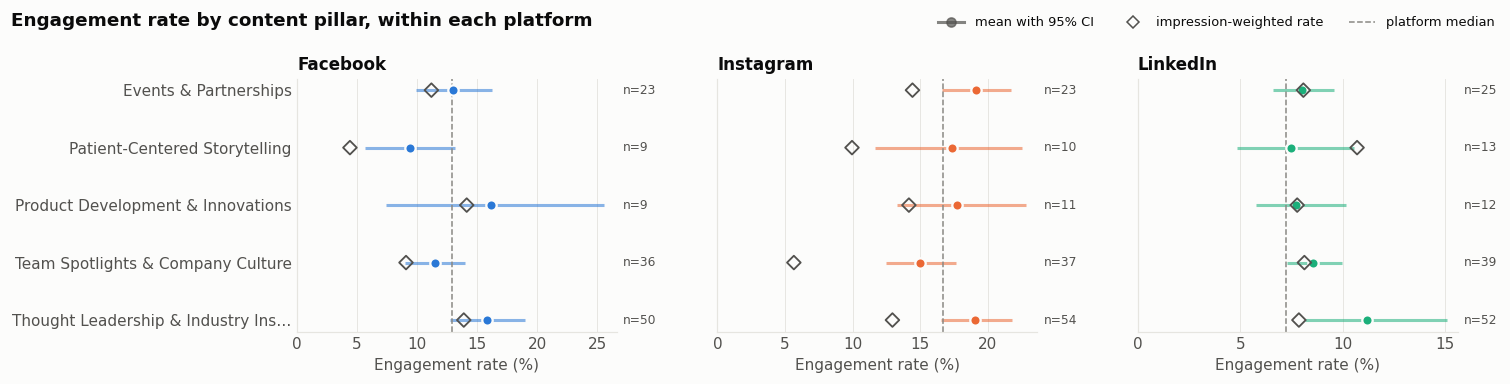

n                        mean                    weighted                   
PLATFORM                               Facebook Instagram LinkedIn Facebook Instagram LinkedIn Facebook Instagram LinkedIn
PILLAR                                                                                                                    
Events & Partnerships                      23.0      23.0     25.0     13.0      19.1      8.0     11.2      14.4      8.1
Patient-Centered Storytelling               9.0      10.0     13.0      9.4      17.3      7.5      4.4      10.0     10.7
Product Development & Innovations           9.0      11.0     12.0     16.1      17.7      7.7     14.1      14.2      7.8
Team Spotlights & Company Culture          36.0      37.0     39.0     11.5      15.0      8.6      9.1       5.7      8.1
Thought Leadership & Industry Insights     50.0      54.0     52.0     15.8      19.0     11.2     13.9      12.9      7.9

In [15]:
pillar_long = explode_tags(posts, "CONTENT_PILLAR", "PILLAR")
pillar_stats = dot_ci_panels(pillar_long, "PILLAR", order=PILLARS,
                             title="Engagement rate by content pillar, within each platform", name="04_pillar")
display(pillar_stats.pivot(index="PILLAR", columns="PLATFORM", values=["n", "mean", "weighted"]).round(1))

### 4.2 ICP segment

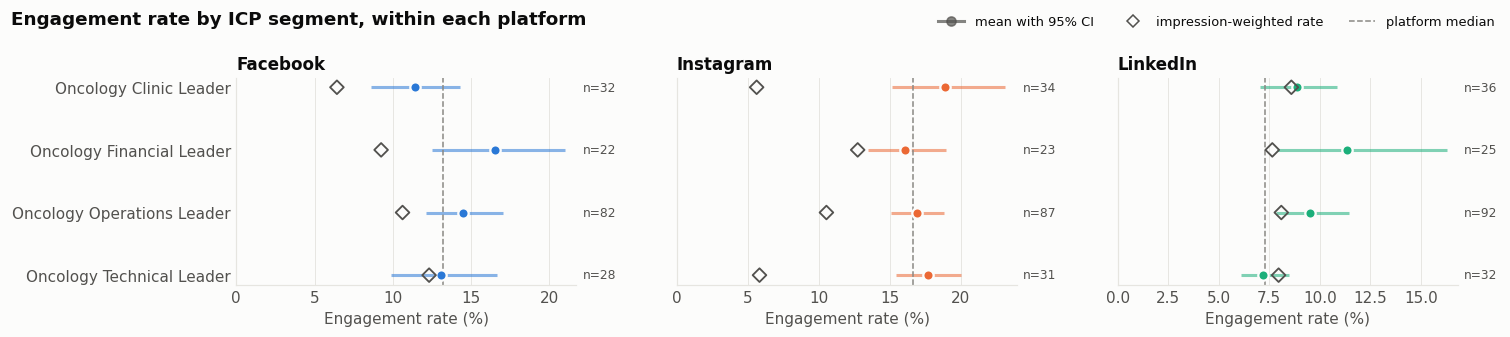

n                        mean                    weighted                   
PLATFORM                   Facebook Instagram LinkedIn Facebook Instagram LinkedIn Facebook Instagram LinkedIn
ICP                                                                                                           
Oncology Clinic Leader         32.0      34.0     36.0     11.4      18.9      8.8      6.4       5.6      8.6
Oncology Financial Leader      22.0      23.0     25.0     16.5      16.1     11.4      9.3      12.7      7.6
Oncology Operations Leader     82.0      87.0     92.0     14.5      16.9      9.5     10.6      10.5      8.1
Oncology Technical Leader      28.0      31.0     32.0     13.1      17.7      7.2     12.3       5.8      8.0

In [16]:
icp_long = explode_tags(posts, "ICP_SEGMENTS", "ICP")
icp_stats = dot_ci_panels(icp_long, "ICP", order=ICPS,
                          title="Engagement rate by ICP segment, within each platform", name="04_icp")
display(icp_stats.pivot(index="ICP", columns="PLATFORM", values=["n", "mean", "weighted"]).round(1))

**Single- vs. multi-segment posts.** Because multi-segment posts appear in several ICP groups, a cleaner
comparison is posts targeting exactly one segment vs. several.

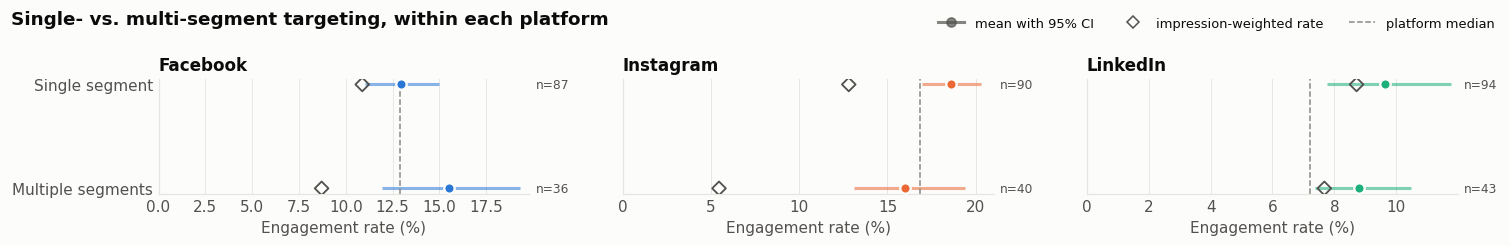

In [17]:
posts["ICP_SCOPE"] = np.where(posts["N_ICP"] > 1, "Multiple segments", "Single segment")
scope_stats = dot_ci_panels(posts, "ICP_SCOPE", order=["Single segment", "Multiple segments"],
                            title="Single- vs. multi-segment targeting, within each platform", name="04_icp_scope")

### 4.3 Format
Formats are platform-specific (Carousel only on Instagram, Document and Simple Status only on LinkedIn), so each
panel shows only the formats that platform has. Empty rows mean the format does not exist there; they are not zero.

PLATFORM,Facebook,Instagram,LinkedIn,All
FORMAT,,,,
Carousel,0,28,0,28
Document,0,0,13,13
Image,79,88,77,244
Link,8,0,18,26
Multi-Image,22,0,10,32
Simple Status,0,0,6,6
Video,15,14,13,42
All,124,130,137,391


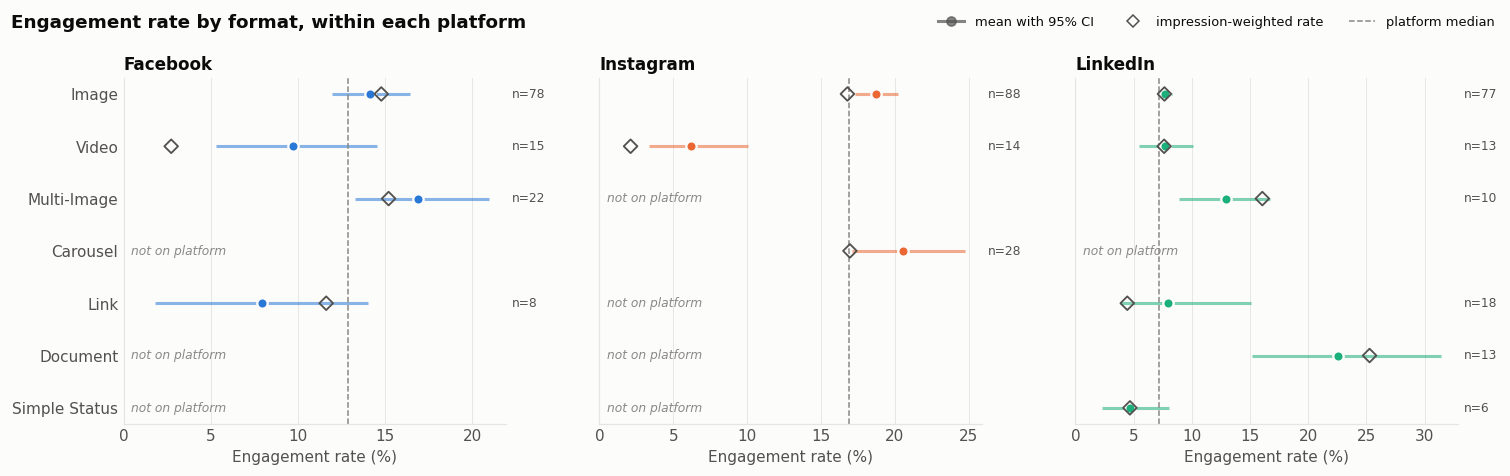

In [18]:
display(pd.crosstab(posts["FORMAT"], posts["PLATFORM"], margins=True))
format_order = posts["FORMAT"].value_counts().index.tolist()
format_stats = dot_ci_panels(posts, "FORMAT", order=format_order,
                             title="Engagement rate by format, within each platform", name="04_format")

**Two checks behind the format chart.**
1. *Are videos simply reaching more people?* If video impressions are systematically larger, a low video rate
   may reflect how reach is counted (e.g. autoplay views), not weaker content.
2. *When did each LinkedIn format run?* A format used only in one period carries that period's conditions
   with it, so its rate cannot be separated from timing.

In [19]:
reach_by_format = (posts.assign(IS_VIDEO=np.where(posts["FORMAT"] == "Video", "Video", "Other formats"))
                   .groupby(["PLATFORM", "IS_VIDEO"])["IMPRESSIONS"].agg(["count", "median", "mean"]).round(0))
display(reach_by_format)

li_format_timing = (posts[posts["PLATFORM"] == "LinkedIn"].groupby("FORMAT")
                    .agg(n=("DATE_TS", "size"), first=("DATE_TS", "min"), last=("DATE_TS", "max"),
                         share_in_experiment=("FLAG_EXPERIMENT", "mean")))
li_format_timing[["first", "last"]] = li_format_timing[["first", "last"]].apply(lambda c: c.dt.date)
display(li_format_timing.round(2))

count  median   mean
PLATFORM  IS_VIDEO                           
Facebook  Other formats    109    17.0   24.0
          Video             15    95.0  105.0
Instagram Other formats    116    23.0   26.0
          Video             14   159.0  224.0
LinkedIn  Other formats    124   240.0  423.0
          Video             13   259.0  256.0

,n,first,last,share_in_experiment
FORMAT,,,,
Document,13,2026-07-15,2026-09-24,1.00
Image,77,2025-10-16,2026-09-29,0.47
Link,18,2025-10-07,2026-09-11,0.17
Multi-Image,10,2025-10-02,2026-07-08,0.90
Simple Status,6,2025-10-06,2026-07-30,0.33
Video,13,2026-02-23,2026-09-22,0.77


**What section 4 shows** (all comparisons within one platform)

- **Content pillar:** no pillar is clearly separated from the others on any platform. Most CIs overlap the
  platform median. Two weaker hints: *Patient-Centered Storytelling* sits at the low end on Facebook (n=9), and on
  Instagram *Team Spotlights & Company Culture* has a much lower weighted rate (5.7%) than its mean (15.0%), meaning
  its high-reach posts underperform. LinkedIn's *Thought Leadership* mean (11.2%) is pulled up by a few outliers;
  its weighted rate (7.9%) matches the other pillars.
- **ICP segment:** no segment stands apart on any platform, and the CIs overlap heavily. Posts are tagged to
  *Operations Leader* far more than any other segment (82–92 per platform), so the other three segments carry
  less information. Single- vs. multi-segment targeting also shows no clear difference.
- **Format: the strongest signal in the content features, with two caveats.**
  - **Video** has the lowest rate on Facebook and Instagram, especially impression-weighted (≈2–3%). But videos
    reach 5–7× more impressions than other formats on those platforms, so part of the gap is a denominator
    effect. Model video together with impressions, not as a standalone rate comparison.
  - **LinkedIn Document** posts have the highest rate in the dataset (mean ≈23%, CI ≈15–31%, n=13), and
    Multi-Image is also above the LinkedIn median. However, every Document post is from Jul–Sep 2026, inside the
    experiment period (and 90% of Multi-Image posts are too), so these format effects are confounded with timing.
    They are hypotheses to test, not findings yet.
  - LinkedIn *Simple Status* (n=6) is the lowest LinkedIn format.

## 5. Timing: day of week and time of day
Posting times are US Central (CDT/CST), as recorded by Loomly. Posts are usually cross-posted to all three
platforms at about the same time, so the platforms share a posting schedule.

### 5.1 When does Hidalga post?
Counts of posts by day × time block. Darker = more posts. Empty cells are slots never used.

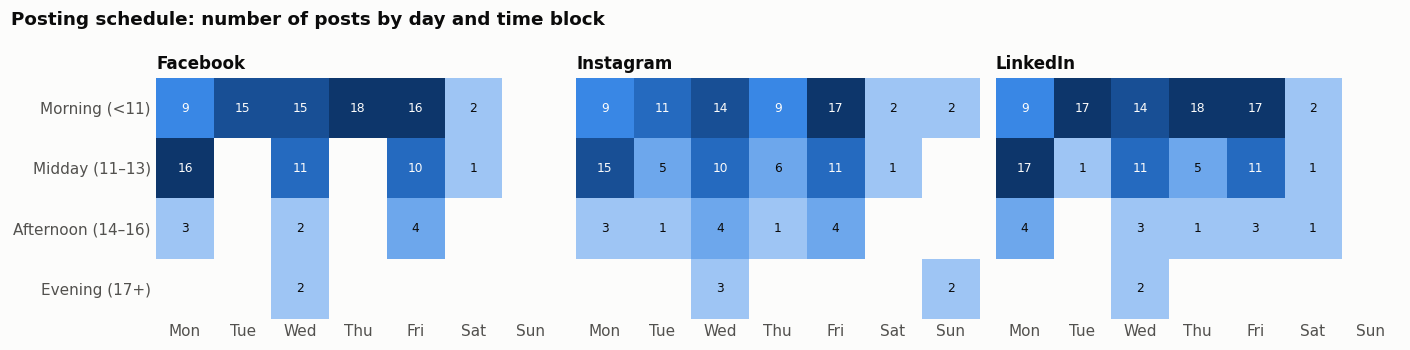

In [20]:
fig, axes = platform_panels(height=3.2, width=4.3)
vmax = posts.groupby(["PLATFORM", "DOW", "TIME_BLOCK"], observed=False).size().max()
cmap = plt.matplotlib.colors.ListedColormap([SURFACE] + BLUE_RAMP)
bounds = [0, 0.5] + list(np.linspace(1, vmax + 1, len(BLUE_RAMP)))
norm = plt.matplotlib.colors.BoundaryNorm(bounds, cmap.N)
for ax, p in zip(axes, PLATFORMS):
    grid = (posts[posts["PLATFORM"] == p].groupby(["TIME_BLOCK", "DOW"], observed=False).size()
            .unstack("DOW").reindex(index=BLOCK_ORDER, columns=DOW_ORDER).fillna(0))
    ax.imshow(grid.values, cmap=cmap, norm=norm, aspect="auto")
    for (i, j), v in np.ndenumerate(grid.values):
        if v:
            ax.text(j, i, int(v), ha="center", va="center", fontsize=8,
                    color=SURFACE if v > vmax * 0.45 else INK)
    ax.set_xticks(range(7), DOW_ORDER)
    ax.set_yticks(range(len(BLOCK_ORDER)), BLOCK_ORDER if p == "Facebook" else [""] * len(BLOCK_ORDER))
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Posting schedule: number of posts by day and time block", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
save(fig, "05_schedule_heatmap")
plt.show()

### 5.2 Engagement by day of week

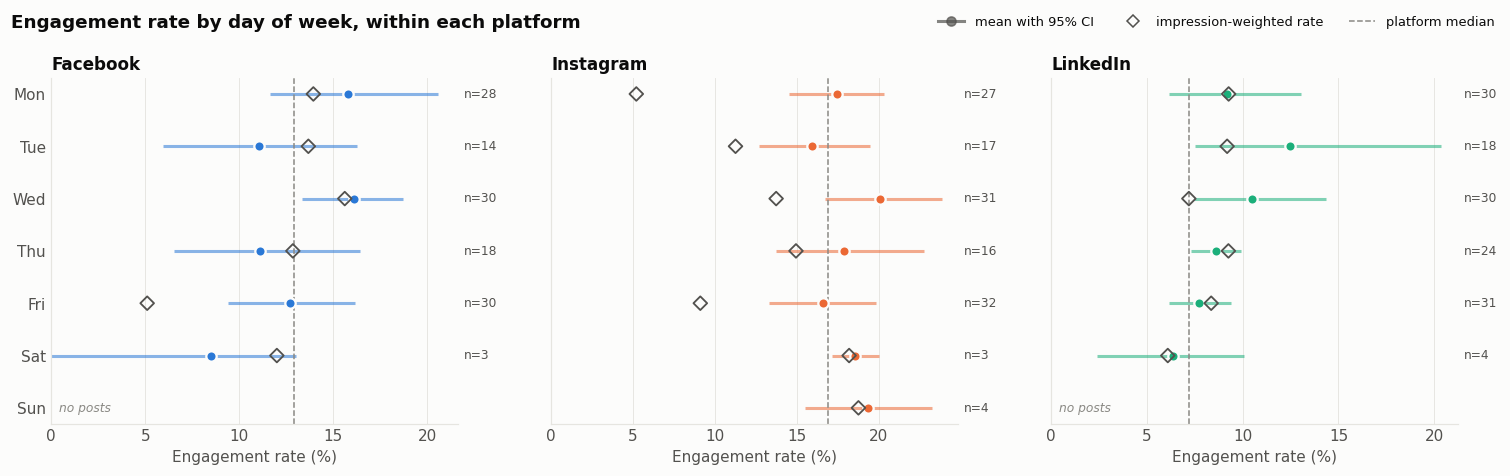

In [21]:
dow_stats = dot_ci_panels(posts, "DOW", order=DOW_ORDER, absent_label="no posts",
                          title="Engagement rate by day of week, within each platform", name="05_dow")

### 5.3 Engagement by time of day

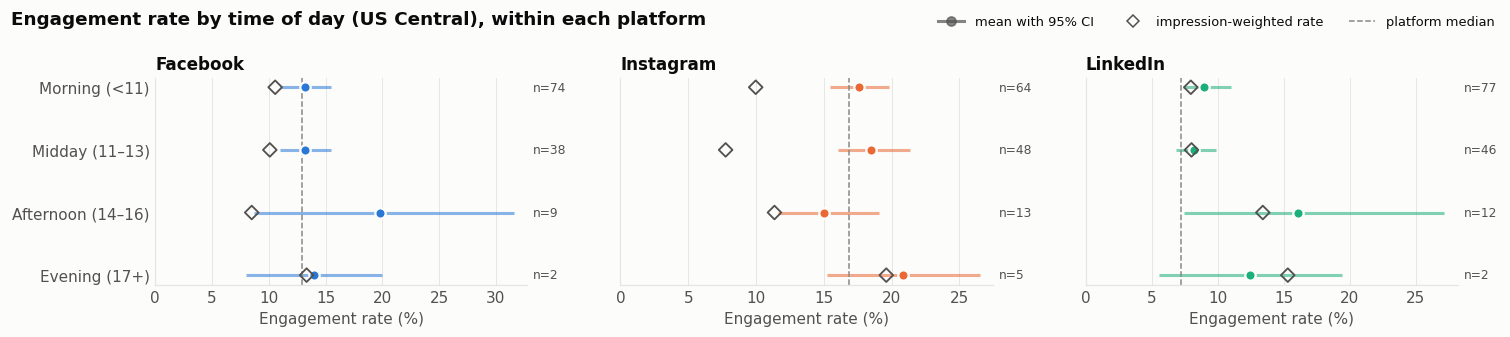

PLATFORM,Facebook,Instagram,LinkedIn
TIME_BLOCK,,,
Afternoon (14–16),9,13,12
Evening (17+),2,5,2
Midday (11–13),38,48,46
Morning (<11),74,64,77


In [22]:
block_stats = dot_ci_panels(posts, "TIME_BLOCK", order=BLOCK_ORDER, absent_label="no posts",
                            title="Engagement rate by time of day (US Central), within each platform",
                            name="05_time_block")
display(block_stats.pivot(index="TIME_BLOCK", columns="PLATFORM", values="n"))

**What section 5 shows**

- The schedule is highly concentrated: about 85–90% of posts go out on weekday mornings or middays, and the three
  platforms follow nearly the same grid (cross-posting). Sunday is used only on Instagram (4 posts).
- **No day or time block is distinguishable** from the others on any platform; every CI overlaps the platform
  median. Afternoon and evening look higher on Facebook and LinkedIn, but with n = 2–12 and very wide CIs.
- Because so few posts fall outside weekday mornings/middays, this data **cannot** say whether other slots would
  do better. That would take deliberate testing. For modeling, a coarse feature (weekday vs. weekend,
  morning vs. later) is the most the data supports.

## 6. Trends over time and the experiment period

The experiment period (Q2–Q3 2026, Apr 1 – Sep 30) is shaded. **Caution:** the flag marks a calendar window, so
anything else that changed over the same months (audience growth, format mix, posting volume) is mixed into it.

### 6.1 Posting volume per month

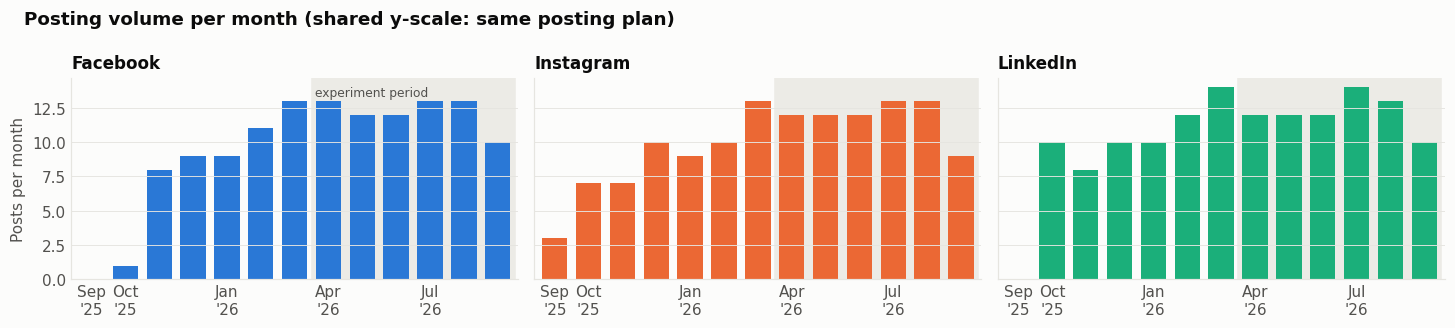

In [23]:
months = pd.period_range(posts["MONTH"].min(), posts["MONTH"].max(), freq="M")
x = np.arange(len(months))
exp_idx = [i for i, m in enumerate(months) if EXPERIMENT_START.to_period("M") <= m <= EXPERIMENT_END.to_period("M")]


def shade_experiment(ax, label=True):
    ax.axvspan(exp_idx[0] - 0.5, exp_idx[-1] + 0.5, color=EXPERIMENT_FILL, zorder=0)
    if label:
        ax.annotate("experiment period", (exp_idx[0] - 0.4, 1), xycoords=("data", "axes fraction"),
                    xytext=(0, -12), textcoords="offset points", fontsize=8, color=INK_2)


def month_axis(ax):
    ax.set_xticks(x, [m.strftime("%b\n'%y") if (m.month in (1, 4, 7, 10) or i == 0) else "" for i, m in enumerate(months)])
    ax.set_xlim(-0.6, len(months) - 0.4)
    ax.grid(axis="x", visible=False)


fig, axes = platform_panels(height=3.0, sharey=True)
for ax, p in zip(axes, PLATFORMS):
    counts = posts[posts["PLATFORM"] == p].groupby("MONTH").size().reindex(months, fill_value=0)
    shade_experiment(ax, label=p == "Facebook")
    ax.bar(x, counts.values, width=0.75, color=PLATFORM_COLOR[p])
    month_axis(ax)
axes[0].set_ylabel("Posts per month")
fig.suptitle("Posting volume per month (shared y-scale: same posting plan)", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
save(fig, "06_volume")
plt.show()

### 6.2 Engagement rate per month
Monthly mean with 95% CI (with ~10 posts per month the CIs are wide) and the impression-weighted rate.
Months with fewer than 3 scored posts are drawn without a CI.

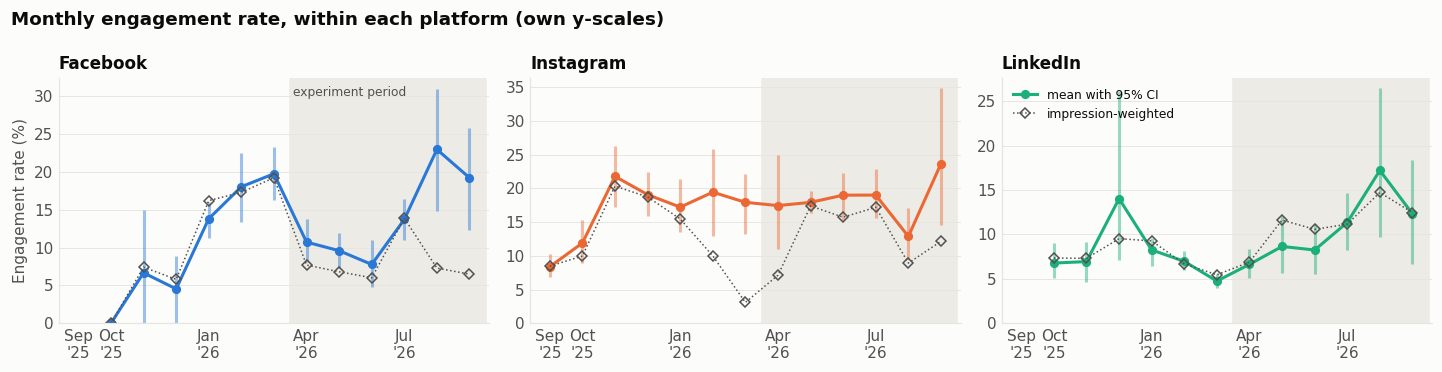

In [24]:
fig, axes = platform_panels(height=3.4)
monthly = summarize(posts, ["PLATFORM", "MONTH"])
for ax, p in zip(axes, PLATFORMS):
    m = monthly[monthly["PLATFORM"] == p].set_index("MONTH").reindex(months)
    shade_experiment(ax, label=p == "Facebook")
    c = PLATFORM_COLOR[p]
    ok = m["n"] >= 3
    ax.vlines(x[ok], m.loc[ok, "ci_lo"], m.loc[ok, "ci_hi"], color=c, lw=2, alpha=0.45)
    ax.plot(x, m["mean"], color=c, marker="o", ms=5, lw=2, label="mean with 95% CI")
    ax.plot(x, m["weighted"], color=INK_2, marker="D", ms=5, lw=1, ls=":", markerfacecolor="none",
            label="impression-weighted")
    ax.set_ylim(bottom=0)
    month_axis(ax)
axes[0].set_ylabel("Engagement rate (%)")
axes[-1].legend(fontsize=8, loc="upper left")
fig.suptitle("Monthly engagement rate, within each platform (own y-scales)", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
save(fig, "06_monthly_rate")
plt.show()

### 6.3 Experiment period vs. before, within platform
Two views: all posts, then **Image posts only**. Image is the one format used throughout the whole year on every
platform, so restricting to it removes most of the format-mix change between periods.

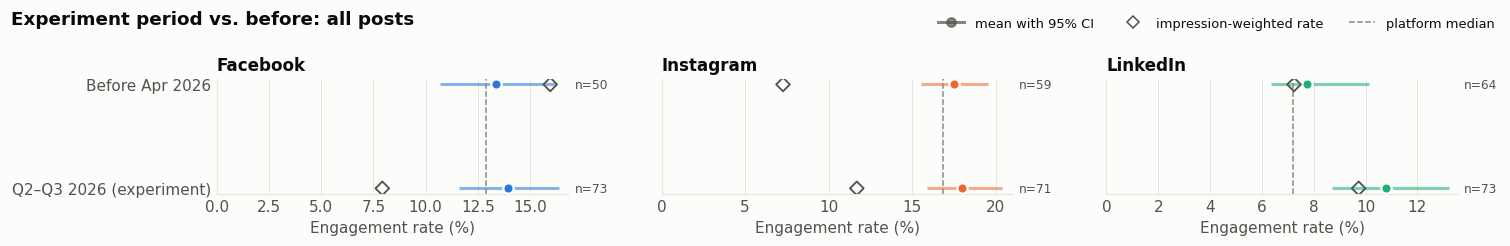

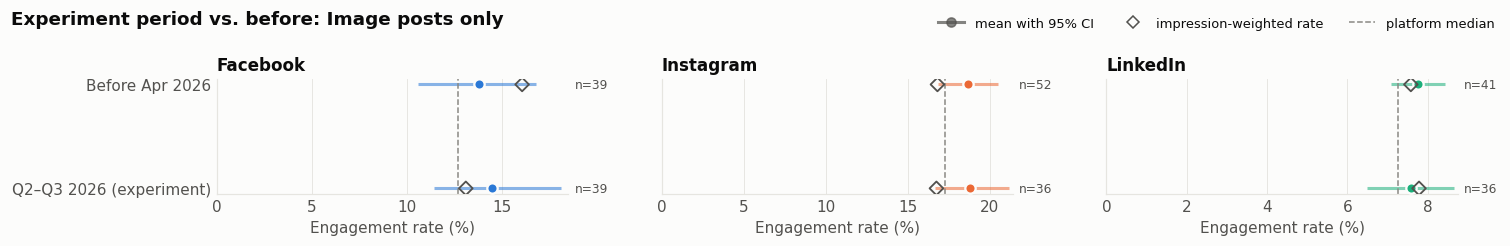

all posts                Image only               
                                          n  mean weighted          n  mean weighted
PLATFORM  PERIOD                                                                    
Facebook  Before Apr 2026                50  13.4     16.0         39  13.8     16.1
          Q2–Q3 2026 (experiment)        73  13.9      7.9         39  14.5     13.1
Instagram Before Apr 2026                59  17.5      7.3         52  18.7     16.8
          Q2–Q3 2026 (experiment)        71  18.0     11.7         36  18.8     16.8
LinkedIn  Before Apr 2026                64   7.8      7.2         41   7.8      7.6
          Q2–Q3 2026 (experiment)        73  10.8      9.7         36   7.6      7.8

In [25]:
posts["PERIOD"] = np.where(posts["FLAG_EXPERIMENT"], "Q2–Q3 2026 (experiment)", "Before Apr 2026")
PERIOD_ORDER = ["Before Apr 2026", "Q2–Q3 2026 (experiment)"]
period_all = dot_ci_panels(posts, "PERIOD", order=PERIOD_ORDER,
                           title="Experiment period vs. before: all posts", name="06_period_all")
period_img = dot_ci_panels(posts[posts["FORMAT"] == "Image"], "PERIOD", order=PERIOD_ORDER,
                           title="Experiment period vs. before: Image posts only", name="06_period_image")
display(pd.concat({"all posts": period_all.set_index(["PLATFORM", "PERIOD"]),
                   "Image only": period_img.set_index(["PLATFORM", "PERIOD"])}, axis=1)
        .loc[:, (slice(None), ["n", "mean", "weighted"])].round(1))

**Format mix by period** shows what changed between the two windows.

In [26]:
display((pd.crosstab([posts["PLATFORM"], posts["FORMAT"]], posts["PERIOD"], normalize="index") * 100)
        .round(0).astype(int).rename(columns=lambda c: f"% in {c}"))

PERIOD                   % in Before Apr 2026  % in Q2–Q3 2026 (experiment)
PLATFORM  FORMAT                                                           
Facebook  Image                            51                            49
          Link                             75                            25
          Multi-Image                       5                            95
          Video                            27                            73
Instagram Carousel                         11                            89
          Image                            59                            41
          Video                            29                            71
LinkedIn  Document                          0                           100
          Image                            53                            47
          Link                             83                            17
          Multi-Image                      10                            90
          Simple Status                    67                            33
          Video                            23                            77

**What section 6 shows**

- **Volume** grew from about 7–10 posts/month in late 2025 to a steady 12–14 in 2026, and held there through the
  experiment period.
- **Facebook:** rate climbed Dec–Mar, dipped Apr–Jun, and rose again Jul–Sep. In Aug–Sep the weighted rate stays
  low while the mean rises, so the higher-reach posts (videos) did not share in that rise.
- **Instagram:** the monthly mean is flat at around 17–19%. The weighted rate dips in Feb–Apr when high-reach
  videos ran.
- **LinkedIn:** a steady rise from about 5% (Mar) to 11–17% (Jul–Sep), the same months Document posts were introduced.
- **Experiment period vs. before:** across all posts only LinkedIn shows a lift (7.8% → 10.8%). **Restricted to
  Image posts, no platform changes between periods** (FB 13.8 → 14.5, IG 18.7 → 18.8, LI 7.8 → 7.6). The format-mix
  table shows why: Multi-Image, Carousel, Video and Document posts are 70–100% concentrated in the experiment
  window. So the period differences come from *what* was posted (format mix), not from a general shift in
  engagement.
- **Modeling implication:** `IN_EXPERIMENT_PERIOD` and the newer formats are heavily collinear. Expect the
  experiment flag to add little once format is in the model, and expect unstable estimates if both are included
  with this sample size. Note that in the Image-only chart the dashed line is the Image-only median.

## 7. Tag combinations and cross-posting

### 7.1 How much content is shared across platforms?
Most content is published to several platforms. A *content piece* here is a normalized title + post date. This
matters for modeling: rows from the same piece on different platforms are not independent observations, which is
one more reason to analyse within platform (or cluster by content piece when pooling).

In [27]:
posts["CONTENT_KEY"] = (posts["POST_TITLE"].str.lower().str.replace(r"\W+", " ", regex=True).str.strip()
                        + " | " + posts["DATE_TS"].dt.strftime("%Y-%m-%d"))
platforms_per_piece = posts.groupby("CONTENT_KEY")["PLATFORM"].nunique()
print(f"{posts['CONTENT_KEY'].nunique()} distinct content pieces across {len(posts)} posts")
display(platforms_per_piece.value_counts().sort_index().rename_axis("platforms per piece").to_frame("pieces"))

169 distinct content pieces across 391 posts


,pieces
platforms per piece,
1,45
2,26
3,98


**Do cross-posted pieces carry the same tags on every platform?** If tags differed by platform, the tag
comparisons in section 4 would mix tagging decisions with content.

In [28]:
multi = posts[posts["CONTENT_KEY"].map(platforms_per_piece) > 1]
tag_consistency = multi.groupby("CONTENT_KEY").agg(icp_variants=("ICP_SEGMENTS", "nunique"),
                                                    pillar_variants=("CONTENT_PILLAR", "nunique"),
                                                    format_variants=("FORMAT", "nunique"))
display((tag_consistency > 1).sum().rename("pieces with differing values across platforms").to_frame())

,pieces with differing values across platforms
icp_variants,1
pillar_variants,0
format_variants,40


### 7.2 Which ICP segments are paired with which pillars?
Counts of *distinct content pieces* (not platform rows, to avoid triple-counting cross-posts), with multi-tag
pieces counted once per tag combination. This describes the content plan; it is not an engagement comparison.

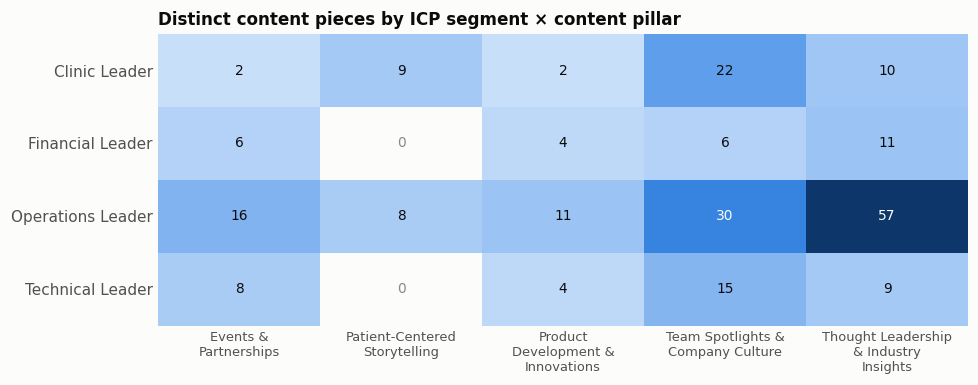

In [29]:
pieces = posts.drop_duplicates("CONTENT_KEY")
combo = (explode_tags(explode_tags(pieces, "ICP_SEGMENTS", "ICP"), "CONTENT_PILLAR", "PILLAR")
         .groupby(["ICP", "PILLAR"]).size().unstack("PILLAR").reindex(index=ICPS, columns=PILLARS).fillna(0))
fig, ax = plt.subplots(figsize=(9, 3.6))
cmap_c = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blue", BLUE_RAMP)
cmap_c.set_bad(SURFACE)   # zero = combination never used, left blank rather than tinted
ax.imshow(np.ma.masked_equal(combo.values, 0), cmap=cmap_c, aspect="auto", vmin=1)
for (i, j), v in np.ndenumerate(combo.values):
    ax.text(j, i, int(v), ha="center", va="center", fontsize=9,
            color=SURFACE if v > combo.values.max() * 0.5 else (INK_MUTED if v == 0 else INK))
ax.set_xticks(range(len(PILLARS)), [textwrap.fill(p, 18) for p in PILLARS], fontsize=8.5)
ax.set_yticks(range(len(ICPS)), [i.replace("Oncology ", "") for i in ICPS])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Distinct content pieces by ICP segment × content pillar")
fig.tight_layout()
save(fig, "07_icp_pillar")
plt.show()

**What section 7 shows**

- The 391 posts are **169 distinct content pieces**: 98 went to all three platforms, 26 to two, 45 to one.
  Platform rows of the same piece are not independent, so any pooled model should cluster by content piece.
- Tags are applied consistently across platforms (1 piece differs on ICP, none on pillar), so the within-platform
  tag comparisons in section 4 compare the same tagging decisions. Format differs for 40 cross-posted pieces,
  e.g. a Carousel on Instagram is a Multi-Image post on Facebook.
- The content plan is dominated by **Operations Leader × Thought Leadership** (57 pieces). Patient-Centered
  Storytelling was never paired with Financial or Technical Leader. Those ICP × pillar combinations cannot be
  evaluated from this data.
- **Opportunity for later:** since most pieces ran on every platform, the same content can be compared across
  formats/platforms *as a matched set*, which controls for the content itself. That is a modeling design choice,
  not something this EDA concludes.

## 8. Supporting data
These sheets are account- or page-level (not per post). They give context for the post-level analysis and are
candidates for features (e.g. audience size at posting time). Data-quality notes appear next to each.

### 8.1 Monthly follower counts and impressions (Loomly rollup, 2026)
**Data notes:** month labels are inconsistently cased ("mar", "Sept"), normalized here in memory only. LinkedIn's
January follower count is **0**, which is almost certainly a missing value rather than a true zero (Feb = 794). It is
drawn as a gap. Each channel is on its own y-scale; follower counts differ by ~40× between channels.

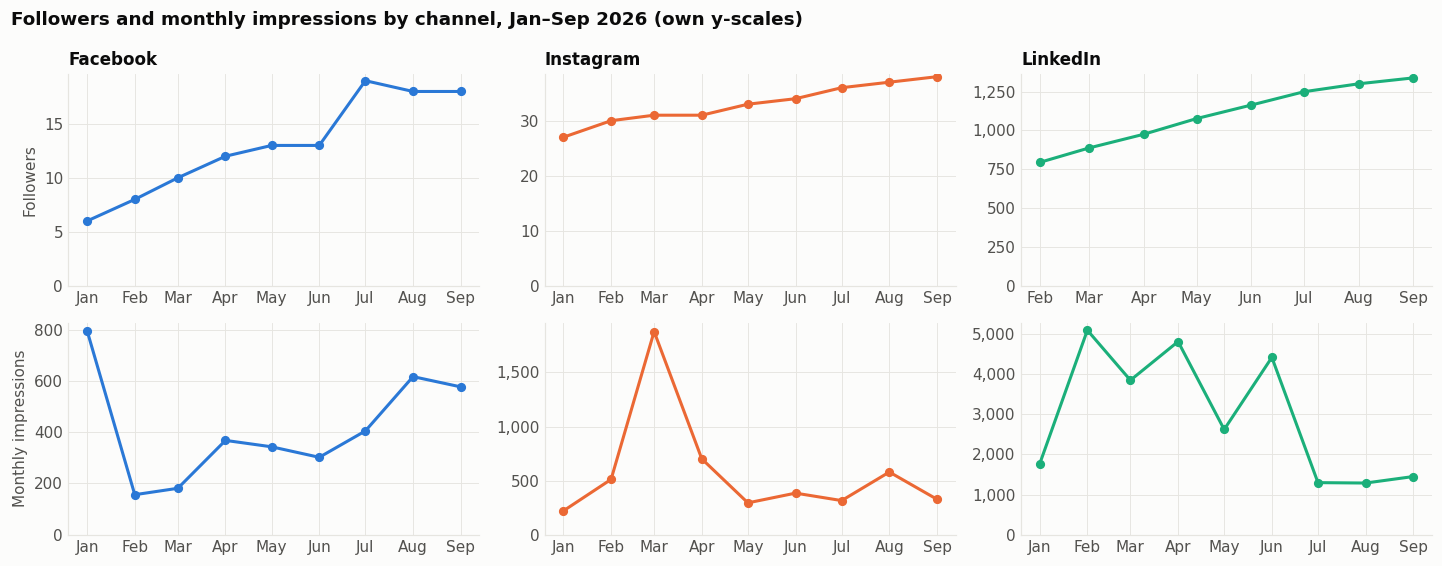

In [30]:
fc = sheets["Follower Counts"].copy()
fc["MONTH_NUM"] = pd.to_datetime(fc["MONTH"].str[:3].str.title(), format="%b").dt.month
fc["MONTH_TS"] = pd.to_datetime(dict(year=2026, month=fc["MONTH_NUM"], day=1))
fc["PLATFORM"] = fc["CHANNEL"].replace({"Linkedin": "LinkedIn"})
fc["FOLLOWERS_PLOT"] = fc["FOLLOWERS"].mask((fc["PLATFORM"] == "LinkedIn") & (fc["FOLLOWERS"] == 0))
fig, axes = platform_panels(nrows=2, height=2.6)
for j, p in enumerate(PLATFORMS):
    d = fc[fc["PLATFORM"] == p].sort_values("MONTH_TS")
    for i, (col, lab) in enumerate([("FOLLOWERS_PLOT", "Followers"), ("IMPRESSIONS", "Monthly impressions")]):
        ax = axes[i][j]
        ax.plot(d["MONTH_TS"], d[col], color=PLATFORM_COLOR[p], marker="o", ms=5)
        ax.set_ylim(bottom=0)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
        if j == 0:
            ax.set_ylabel(lab)
fig.suptitle("Followers and monthly impressions by channel, Jan–Sep 2026 (own y-scales)", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
save(fig, "08_followers")
plt.show()

### 8.2 LinkedIn page: daily impressions and new followers
7-day rolling averages. Organic and sponsored impressions are shown separately because paid boosts produce large
spikes that would otherwise swamp the organic trend.

Sponsored share of LinkedIn page impressions: 92.9%; days with any sponsored impressions: 31


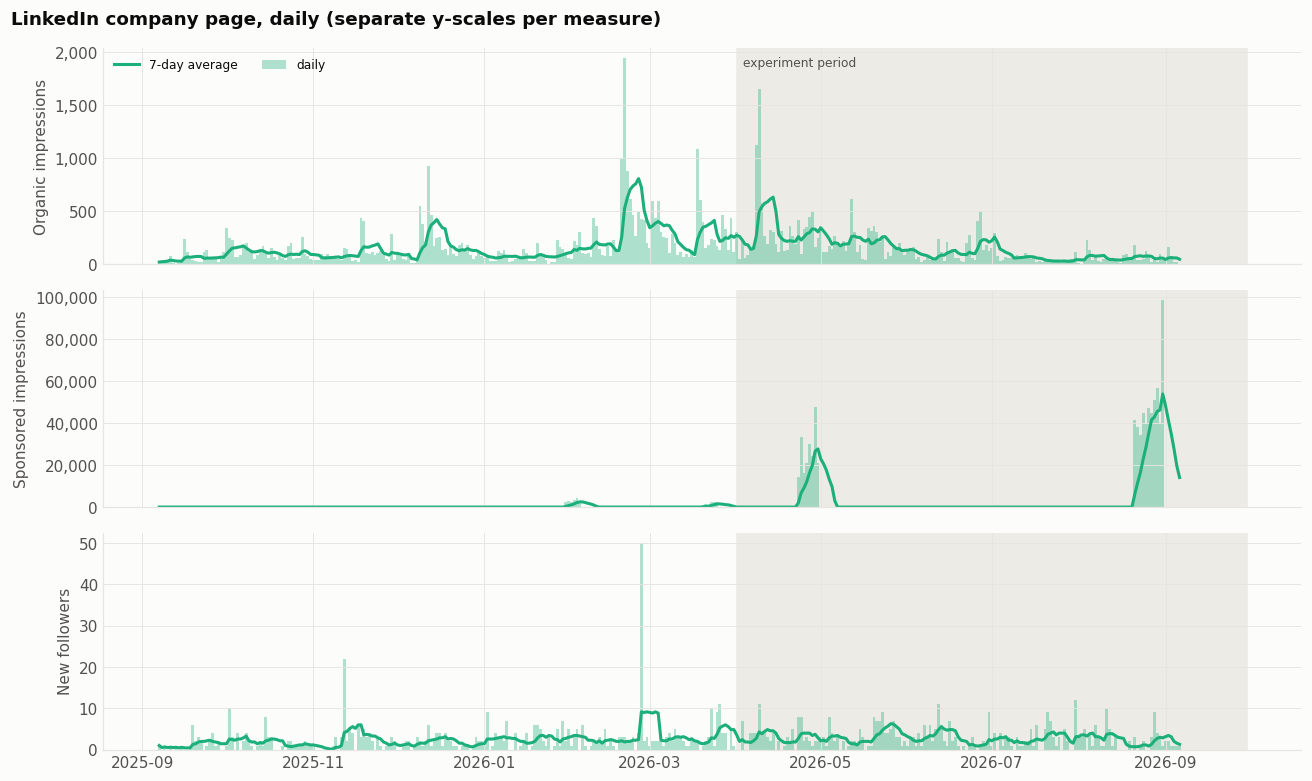

In [31]:
lid = sheets["LinkedIn Daily Metrics"].sort_values("DATE").set_index("DATE")
nf = sheets["LinkedIn New Followers (daily)"].sort_values("DATE").set_index("DATE")
print("Sponsored share of LinkedIn page impressions: "
      f"{lid['Impressions (sponsored)'].sum() / lid['Impressions (total)'].sum():.1%}; "
      f"days with any sponsored impressions: {(lid['Impressions (sponsored)'] > 0).sum()}")

fig, axes = plt.subplots(3, 1, figsize=(12, 7.2), sharex=True)
series = [(lid["Impressions (organic)"], "Organic impressions"),
          (lid["Impressions (sponsored)"], "Sponsored impressions"),
          (nf["Total followers"], "New followers")]
for ax, (s, lab) in zip(axes, series):
    ax.axvspan(EXPERIMENT_START, EXPERIMENT_END, color=EXPERIMENT_FILL, zorder=0)
    ax.bar(s.index, s.values, width=1, color=PLATFORM_COLOR["LinkedIn"], alpha=0.35, label="daily")
    ax.plot(s.rolling(7, min_periods=1).mean(), color=PLATFORM_COLOR["LinkedIn"], lw=2, label="7-day average")
    ax.set_ylabel(lab)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].legend(fontsize=8, loc="upper left", ncol=2)
axes[0].annotate("experiment period", (EXPERIMENT_START, 1), xycoords=("data", "axes fraction"), xytext=(4, -12),
                 textcoords="offset points", fontsize=8, color=INK_2)
fig.suptitle("LinkedIn company page, daily (separate y-scales per measure)", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
save(fig, "08_linkedin_daily")
plt.show()

### 8.3 LinkedIn page visitors and who they are

Daily page views: median 4, total 2,201 over 365 days; unique visitors/day median 2


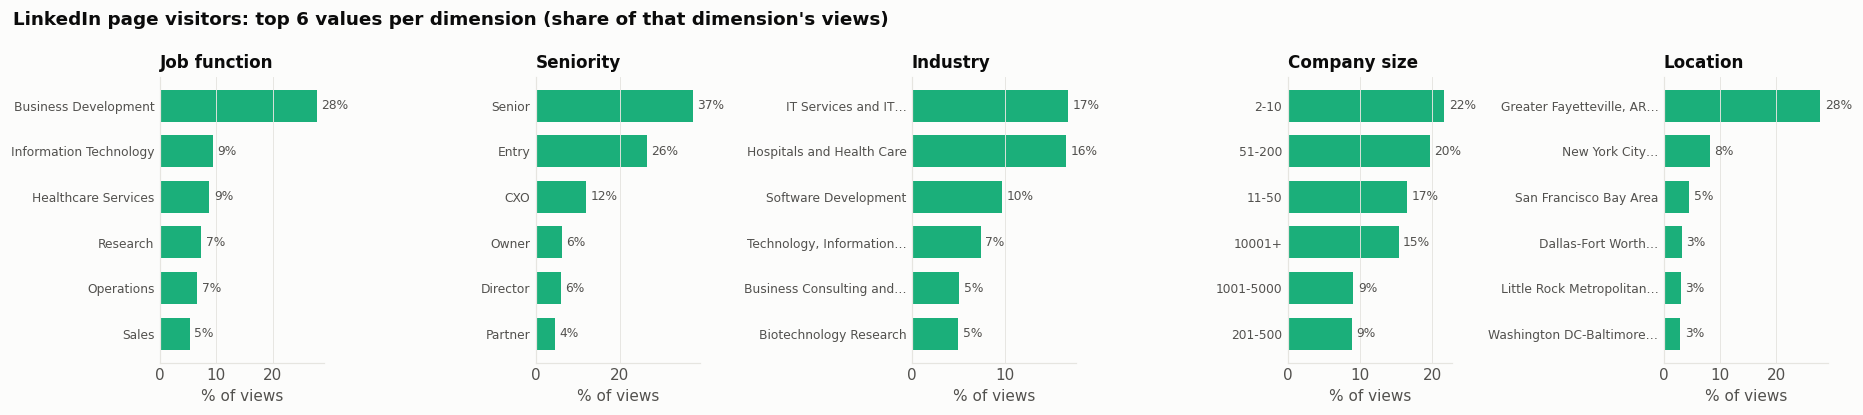

In [32]:
vis = sheets["Visitor Daily Metrics"].sort_values("DATE").set_index("DATE")
print(f"Daily page views: median {vis['Total page views (total)'].median():.0f}, "
      f"total {vis['Total page views (total)'].sum():,.0f} over {len(vis)} days; "
      f"unique visitors/day median {vis['Total unique visitors (total)'].median():.0f}")

demo = sheets["Visitor Demographics"]
dims = ["Job function", "Seniority", "Industry", "Company size", "Location"]
fig, axes = plt.subplots(1, len(dims), figsize=(17, 3.8))
for ax, dim in zip(axes, dims):
    d = demo[demo["DIMENSION"] == dim].nlargest(6, "TOTAL_VIEWS").iloc[::-1]
    share = d["TOTAL_VIEWS"] / demo.loc[demo["DIMENSION"] == dim, "TOTAL_VIEWS"].sum() * 100
    ax.barh([textwrap.shorten(v, 26, placeholder="…") for v in d["DIMENSION_VALUE"]], share,
            color=PLATFORM_COLOR["LinkedIn"], height=0.7)
    for yi, v in enumerate(share):
        ax.annotate(f"{v:.0f}%", (v, yi), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8,
                    color=INK_2)
    ax.set_title(dim)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("% of views")
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("LinkedIn page visitors: top 6 values per dimension (share of that dimension's views)", x=0.01,
             ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout()
save(fig, "08_visitor_demographics")
plt.show()

### 8.4 Loomly short-link clicks
**Data note:** 13 of 95 links have no click total (blank, not zero). They are counted separately below, not as 0.
These links cannot be joined to individual posts (no shared key, see README), so this is descriptive only.

In [33]:
lc = sheets["Loomly Clicks"].copy()
lc["DOMAIN"] = lc["DESTINATION_URL"].str.extract(r"https?://(?:www\.)?([^/]+)")[0]
lc["DEST_GROUP"] = np.where(lc["DOMAIN"].eq("hidalgatech.com"), "hidalgatech.com (own site)", "External articles/sources")
print(f"links: {len(lc)} · with click totals: {lc['TOTAL_CLICKS'].notna().sum()} · blank: {lc['TOTAL_CLICKS'].isna().sum()}")
display(lc.groupby("DEST_GROUP")["TOTAL_CLICKS"].agg(links="size", with_data="count", median="median",
                                                     mean="mean", total="sum").round(1))
display(lc.nlargest(8, "TOTAL_CLICKS")[["CREATION_DATE", "DOMAIN", "TOTAL_CLICKS", "DESTINATION_URL"]])

links: 95 · with click totals: 82 · blank: 13


,links,with_data,median,mean,total
DEST_GROUP,,,,,
External articles/sources,72,61,15.0,16.7,1021.0
hidalgatech.com (own site),23,21,19.0,24.3,511.0


,CREATION_DATE,DOMAIN,TOTAL_CLICKS,DESTINATION_URL
0,2025-09-22,hidalgatech.com,99.0,https://hidalgatech.com/
50,2026-03-20,hidalgatech.com,54.0,https://hidalgatech.com/about/
64,2026-05-26,astro.org,53.0,https://www.astro.org/news-and-publications/astronews/20...
46,2026-03-13,hoparx.org,45.0,https://www.hoparx.org/hopa-learn/conferences-events/ann...
55,2026-03-28,linkedin.com,43.0,https://www.linkedin.com/in/janet-malmberg/
62,2026-05-07,hidalgatech.com,42.0,https://hidalgatech.com/use-case-operational/
53,2026-03-28,ruraloncologyconference.org,39.0,https://www.ruraloncologyconference.org/
80,2026-07-29,ascopubs.org,39.0,https://ascopubs.org/doi/10.1200/OP.2025.21.10_suppl.55?...


### 8.5 Instagram Stories
Only 20 Stories (Feb–Sep 2026), each reaching about 9–12 accounts, with zero replies and zero link clicks recorded.
Too small for analysis. Summarized for completeness.

In [34]:
display(sheets["Instagram Stories"].drop(columns=["SOURCE_FILE", "STORY", "LABELS_RAW"])
        .describe().round(1).T[["count", "mean", "min", "50%", "max"]])

,count,mean,min,50%,max
DATE,20,2026-07-25 11:56:31,2026-02-04 10:05:28,2026-08-12 18:06:12,2026-09-07 17:51:41
EXITS,19.0,2.5,0.0,2.0,5.0
IMPRESSIONS,20.0,9.6,5.0,9.5,12.0
REACH,20.0,9.2,5.0,9.0,12.0
REPLIES,20.0,0.0,0.0,0.0,0.0
TAPS FORWARD,20.0,5.0,2.0,5.0,8.0
TAPS BACK,17.0,0.2,0.0,0.0,1.0
LINK CLICKS,15.0,0.0,0.0,0.0,0.0


### 8.6 Competitor benchmark (LinkedIn pages, Sep 2025 – Sep 2026)
A single annual snapshot per company: useful context, not a time series. Hidalga is highlighted; reactions per post
normalizes for posting volume.

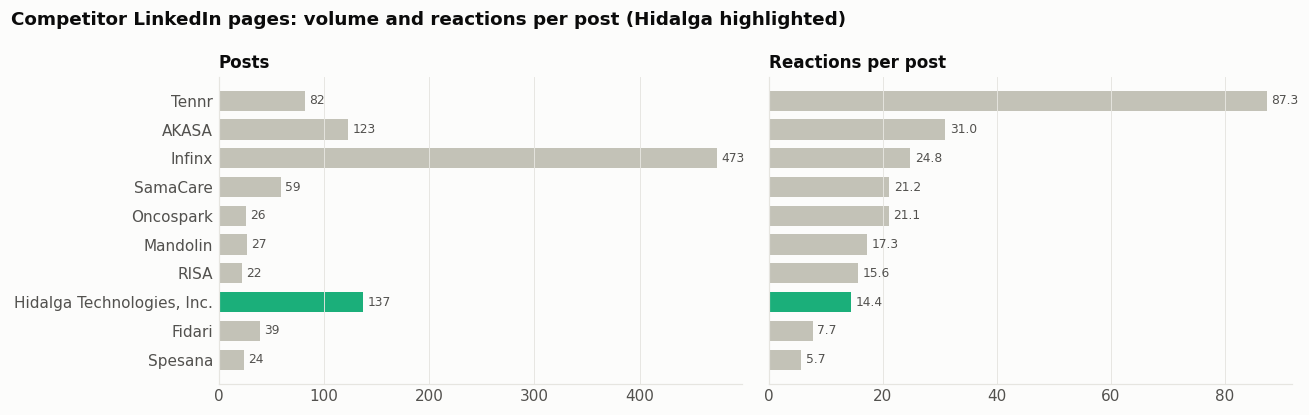

,SNAPSHOT_START_DATE,SNAPSHOT_END_DATE,New Followers,Posts,Comments,Comments per day,Reactions,Reactions per post
Page,,,,,,,,
Spesana,9/7/2025,9/6/2026,33,24,2,0,137,5.7
Fidari,9/7/2025,9/6/2026,160,39,12,0,301,7.7
"Hidalga Technologies, Inc.",9/7/2025,9/6/2026,949,137,180,0,1978,14.4
RISA,9/7/2025,9/6/2026,12581,22,2,0,344,15.6
Mandolin,9/7/2025,9/6/2026,1584,27,30,0,466,17.3
Oncospark,9/7/2025,9/6/2026,1022,26,98,0,549,21.1
SamaCare,9/7/2025,9/6/2026,554,59,41,0,1250,21.2
Infinx,9/7/2025,9/6/2026,42536,473,223,1,11752,24.8
AKASA,9/7/2025,9/6/2026,2711,123,287,1,3813,31.0


In [35]:
comp = sheets["Competitors"].copy()
comp["Reactions per post"] = comp["Reactions"] / comp["Posts"]
comp = comp.sort_values("Reactions per post")
is_h = comp["Page"].str.startswith("Hidalga")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col in zip(axes, ["Posts", "Reactions per post"]):
    ax.barh(comp["Page"], comp[col], height=0.7, color=np.where(is_h, PLATFORM_COLOR["LinkedIn"], "#c3c2b7"))
    for yi, v in enumerate(comp[col]):
        ax.annotate(f"{v:,.0f}" if col == "Posts" else f"{v:,.1f}", (v, yi), xytext=(3, 0),
                    textcoords="offset points", va="center", fontsize=8, color=INK_2)
    ax.set_title(col)
    ax.grid(axis="y", visible=False)
fig.suptitle("Competitor LinkedIn pages: volume and reactions per post (Hidalga highlighted)", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
save(fig, "08_competitors")
plt.show()
display(comp.drop(columns=["SOURCE_FILE"]).set_index("Page").round(1))

**What section 8 shows**

- **Audiences are growing and very different in size.** LinkedIn followers went from 794 (Feb) to 1,338 (Sep), +68%.
  Facebook (6 → 18) and Instagram (27 → 38) audiences are tiny, so most impressions on those platforms come from
  non-followers. Audience growth is a time-varying confounder for any trend in impressions.
- **LinkedIn organic impressions peaked Feb–Apr and fell to low levels Jul–Sep**, while post-level engagement *rates*
  rose over the same months (section 6). A shrinking denominator is one more reason rates rose; the counts did not.
- **Paid boosts are 93% of LinkedIn page impressions** (4 campaigns: late Jan, Mar, late Apr, late Aug). The
  post-level table carries the boosted posts' **organic** numbers (verified against the LinkedIn export), so paid
  reach does not inflate the target. The boosted posts are flagged below, since a boost can still lift organic reach.
- **Visitors** are few (median 4 page views/day). They skew to Business Development (28%), Senior seniority (37%),
  IT services and Hospitals & Health Care, and the Fayetteville, AR area (28%), i.e. the local and professional network
  more than oncology-operations buyers.
- **Loomly links** to Hidalga's own site draw a median of 19 clicks vs. 15 for external articles. Links can't be tied
  to individual posts.
- **Competitors:** Hidalga's volume is the 2nd-highest of 10 pages (137 posts), but its reactions per post (14.4) rank
  8th. That is context for the Stage 2 market-research layer.

## 9. Summary

### 9.1 Data-quality register
Issues found during this EDA. **None were changed here**; v3 stays the source of truth. Items marked *fix in next
master* are candidates for `apply_master_corrections.py` when a new version is produced.

In [36]:
li_rows = posts["PLATFORM"] == "LinkedIn"
BOOSTED_LI_DATES = pd.to_datetime(sheets["LinkedIn Posts (detail)"]
                                  .loc[lambda d: d["Post type"] == "Sponsored", "Created date"]).dt.normalize().unique()
posts["FLAG_BOOSTED"] = li_rows & posts["DATE_TS"].isin(BOOSTED_LI_DATES)
posts["FLAG_DUP_LI_METRICS"] = li_rows & posts["ENGAGEMENT_SOURCE"].str.startswith("LinkedIn") & posts.duplicated(
    ["PLATFORM", "DATE", "IMPRESSIONS", "REACTIONS", "COMMENTS", "SHARES", "CLICKS"], keep=False)

register = pd.DataFrame([
    ("LinkedIn posts sharing one native metrics row", int(posts["FLAG_DUP_LI_METRICS"].sum()),
     "2026-03-20: two different posts both matched the same LinkedIn row (294 impressions); the other row (443) was unused",
     "fix in next master"),
    ("LinkedIn posts that were also paid-boosted", int(posts["FLAG_BOOSTED"].sum()),
     "4 boost campaigns; flagged by date, so both 2026-03-20 posts are included. Organic metrics used (correct); "
     "flag as a covariate since boosts can lift organic reach", "keep, flag"),
    ("LinkedIn posts on Loomly instead of native metrics", int((li_rows & posts["ENGAGEMENT_SOURCE"].eq("Loomly")).sum()),
     "newest posts, after the LinkedIn export's cutoff", "fix with a fresh LinkedIn export"),
    ("Posts with < 10 impressions", int(posts["FLAG_LOW_IMPRESSIONS"].sum()),
     "unstable rates; 24 of them on Facebook (incl. the 0-impression post)", "keep; weight or use count model"),
    ("Post with 0 impressions (null target)", int(posts["FLAG_NO_TARGET"].sum()), "Facebook 2025-12-02", "keep; excluded from rate stats only"),
    ("Follower Counts: LinkedIn January = 0", 1, "almost certainly missing, not zero", "fix in next master"),
    ("Follower Counts: inconsistent month labels", int(sheets["Follower Counts"]["MONTH"].str.contains("^[a-z]|Sept").sum()),
     "'mar', 'apr', …, 'Sept' mixed with 'Jan'", "fix in next master"),
    ("Loomly links with blank click totals", int(sheets["Loomly Clicks"]["TOTAL_CLICKS"].isna().sum()), "blank, not zero",
     "keep; treat as missing"),
], columns=["issue", "rows", "detail", "action"])
display(register)

,issue,rows,detail,action
0,LinkedIn posts sharing one native metrics row,2,2026-03-20: two different posts both matched the same Li...,fix in next master
1,LinkedIn posts that were also paid-boosted,5,"4 boost campaigns; flagged by date, so both 2026-03-20 p...","keep, flag"
2,LinkedIn posts on Loomly instead of native metrics,10,"newest posts, after the LinkedIn export's cutoff",fix with a fresh LinkedIn export
3,Posts with < 10 impressions,27,unstable rates; 24 of them on Facebook (incl. the 0-impr...,keep; weight or use count model
4,Post with 0 impressions (null target),1,Facebook 2025-12-02,keep; excluded from rate stats only
5,Follower Counts: LinkedIn January = 0,1,"almost certainly missing, not zero",fix in next master
6,Follower Counts: inconsistent month labels,18,"'mar', 'apr', …, 'Sept' mixed with 'Jan'",fix in next master
7,Loomly links with blank click totals,13,"blank, not zero",keep; treat as missing


### 9.2 Key findings (all within-platform)

1. **Reach drives the rate.** On Instagram especially, posts with more impressions engage at much lower rates.
   Simple means overstate typical performance (IG mean 17.8% vs. impression-weighted 9.3%).
2. **Format is the clearest content signal.** It has two confounds:
   - Video has the lowest rate on Facebook and Instagram, but videos reach 5–7× more impressions.
   - LinkedIn Document posts have the highest rate in the data (≈23%, n=13), but they all ran Jul–Sep 2026.
3. **Pillar, ICP segment, day and time show no distinguishable differences** at this sample size. Every CI overlaps
   its platform median. Absence of evidence here is not evidence of no effect; the groups are small.
4. **The experiment-period "lift" is format mix.** LinkedIn rose 7.8% → 10.8% overall, but Image posts alone did not
   change on any platform. New formats are 70–100% concentrated in the experiment window.
5. **LinkedIn rates rose as organic impressions fell** (Jul–Sep), and audiences grew throughout. Time trends mix
   content changes, audience growth and denominator effects.
6. **Content is mostly cross-posted** (98 of 169 pieces on all 3 platforms), with consistent tags, so platform rows
   are not independent.

### 9.3 Implications for Stage 1 modeling

- Model **within platform** (or pool with platform interactions) and **cluster standard errors by content piece**.
- Use **engagements as a count with log(impressions) as exposure** (Poisson / negative binomial), or include
  log-impressions as a covariate. Either way, don't model the raw rate as if reach doesn't matter.
- Keep all posts. Low-impression posts are handled by the exposure term rather than by deletion.
- Expect **format and `IN_EXPERIMENT_PERIOD` to be collinear**. Consider format-only models with the period as a
  sensitivity check, and treat LinkedIn Document as a hypothesis that needs more post-July data.
- Use multi-hot (0/1) ICP and pillar features at the post level. Keep timing features coarse.
- Add `FLAG_BOOSTED` as a covariate, and fix the duplicated LinkedIn metrics row before the final model run.

### 9.4 Integrity check
Confirm the master workbook is unchanged and no rows were dropped in this notebook.

In [37]:
assert sha256(MASTER) == MASTER_SHA, "master workbook changed during the notebook run!"
assert len(posts) == len(raw_posts) == 391
print(f"OK: {MASTER.name} unchanged (sha256 {MASTER_SHA[:12]}…), {len(posts)} posts analysed, 0 dropped.")
print(f"Figures saved to {FIG_DIR}/: {len(list(FIG_DIR.glob('*.png')))} PNGs")

OK: Hidalga_Master_Data_v3.xlsx unchanged (sha256 030bd10386b1…), 391 posts analysed, 0 dropped.
Figures saved to figures/: 19 PNGs
